## **X7**: TT - Draws of the Ansatz Parameters θ
* October 10°, 2026
#### ESCOM - IPN:

#### *B.S. in Computer Science*
> Miguel Alexander Sanchez Garcia

#### **0° Introduction**

Architecture B draws the ansatz parameters θ **once**, with seed 42, and never trains them (D-014). H-017 warned that a single draw of θ cannot support a conclusion about the concentration of the embedding, and the sensitivity analysis of Module 7 varied the seed of the MLP but kept θ (D-037). This notebook measures how much the results of C4 and C5 depend on that one draw.

**What θ can and cannot change.** The state of C4 and C5 is $|\psi(\mathbf{x})\rangle = V(\theta)\,U_\Phi(\mathbf{x})\,|0\rangle^{\otimes 12}$.

- The fidelity kernel does not see θ: $|\langle\psi(\mathbf{x})|\psi(\mathbf{x}')\rangle|^2 = |\langle 0|U_\Phi(\mathbf{x})^\dagger V(\theta)^\dagger V(\theta)\,U_\Phi(\mathbf{x}')|0\rangle|^2$ and $V^\dagger V = I$. The kernel metrics of Module 6, X2, the QSVM of X4 and X6 are therefore the same for every θ. This is a property of the formalism (a unitary preserves inner products), not of Qiskit.
- The readout does: $\langle Z_i\rangle = \langle\phi(\mathbf{x})|\,V(\theta)^\dagger Z_i V(\theta)\,|\phi(\mathbf{x})\rangle$. Changing θ changes **which 12 observables** are read from the same encoded state. The embedding metrics of Module 6 and the classification of Module 7 depend on θ.

**Protocol.**

| Element | Choice |
|---|---|
| Inputs | The 12 angles of Module 4, train split only |
| Circuits | `zz_feature_map` (C4) and `pauli_feature_map(paulis=['Y','ZZ'])` (C5), reps = 1, followed by `real_amplitudes(12, reps=1)` |
| Draws of θ | θ ~ U(0, 2π)²⁴ with seeds 42 to 51; seed 42 is the draw of the design |
| Classifier | The MLP of Module 7 with its base configuration (D-036), MLP seed 42 for every draw, so that θ is the only thing that changes |
| Evaluation | 5-fold cross-validation with the folds of Module 4. **The test split is not used**, as in D-037: no draw of θ can be chosen on it |
| References | C1 and C3 of Module 7, and the spread of the MLP over its five seeds (42 to 46) |

#### **1° Setup**

**a.** Libraries, parameters and the draws of θ

In [1]:
import copy
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
import torch
from qiskit.circuit.library import pauli_feature_map, real_amplitudes, zz_feature_map
from qiskit.quantum_info import Statevector
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)
SEED, N_QUBITS = 42, 12
THETA_SEEDS = list(range(42, 52))           # 42 is the draw of the design (D-014)
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
QUANTUM = ['C4', 'C5']
N_FOLDS, BATCH, MAX_EPOCHS, PATIENCE, INNER_VAL = 5, 128, 400, 40, 0.15
CONFIG = dict(hidden=(32, 16), lr=1e-3, weight_decay=1e-4, standardize=True)     # base configuration of Module 7 (D-036)
ROOT = Path('/Users/alexander_san/TT')
M5_DIR, RESULTS_DIR, FIG_DIR = ROOT / 'Data/processed/m5', ROOT / 'Code/results', ROOT / 'Docs/Figures'
COLORS = {'C1': '#eda100', 'C3': '#2a78d6', 'C4': '#eb6834', 'C5': '#1baf7a'}
INK, MUTED = '#3d3d3a', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})

checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})


cols = lambda c: [f'{c}_{j:02d}' for j in range(1, 13)]
frames = {ft: pd.read_parquet(M5_DIR / f'emb_{ft}.parquet').query("split == 'train'").reset_index(drop=True) for ft in FINDINGS}
ansatz = real_amplitudes(N_QUBITS, reps=1)
draws = {s: np.random.default_rng(s).uniform(0, 2 * np.pi, ansatz.num_parameters) for s in THETA_SEEDS}
theta_design = np.array(json.loads((M5_DIR / 'emb_meta.json').read_text())['theta'])
check('theta seed 42 reproduces the theta of Module 5', np.abs(draws[SEED] - theta_design).max(), np.array_equal(draws[SEED], theta_design))
m7 = pd.read_csv(RESULTS_DIR / '7_cv_por_fold.csv')
print(f'qiskit {qiskit.__version__} | torch {torch.__version__} (CPU, deterministic) | numpy {np.__version__}')
for ft, frame in frames.items():
    print(f'{ft:13s}: {len(frame)} train lesions, {int(frame.label.sum())} malignant, {frame.patient_id.nunique()} patients')
print(f'{len(draws)} draws of theta with {ansatz.num_parameters} parameters each')

qiskit 2.3.0 | torch 2.10.0 (CPU, deterministic) | numpy 2.2.6
mass         : 1318 train lesions, 637 malignant, 691 patients
calcification: 1546 train lesions, 544 malignant, 602 patients
10 draws of theta with 24 parameters each


#### **2° Embeddings for every draw**

**a.** Exact ⟨Zᵢ⟩ with the same evaluation as Module 5 (direct `Statevector`, no estimator primitive), with θ as an argument. With seed 42 the result must equal the embedding stored by Module 5 bit for bit.

In [2]:
feature_maps = {'C4': zz_feature_map(N_QUBITS, reps=1), 'C5': pauli_feature_map(N_QUBITS, reps=1, paulis=['Y', 'ZZ'])}
signs = 1.0 - 2.0 * ((np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1)


def exact_embedding(feature_map, x, theta):
    # Module 5, cell 7, with theta as an argument
    values = {p: float(v) for p, v in zip(feature_map.parameters, x)}
    values.update({p: float(v) for p, v in zip(ansatz.parameters, theta)})
    circuit = feature_map.compose(ansatz).assign_parameters(values, inplace=False)
    return Statevector.from_instruction(circuit).probabilities() @ signs


embeddings = {}
t0 = time.perf_counter()
for ft, frame in frames.items():
    x = frame[cols('C1')].to_numpy(float)            # C1 is the angle vector of Module 4
    for q, fm in feature_maps.items():
        for s, theta in draws.items():
            embeddings[(ft, q, s)] = np.vstack([exact_embedding(fm, row, theta) for row in x])
        err = np.abs(embeddings[(ft, q, SEED)] - frame[cols(q)].to_numpy()).max()
        check(f'{ft}: {q} with theta seed 42 equals the embedding of Module 5', err, err == 0)
print(f'{len(embeddings)} embeddings ({sum(len(v) for v in embeddings.values())} states) in {time.perf_counter() - t0:.0f} s')
display(pd.DataFrame(checks))

40 embeddings (57280 states) in 447 s


,check,value,passed
0,theta seed 42 reproduces the theta of Module 5,0.0,True
1,mass: C4 with theta seed 42 equals the embeddi...,0.0,True
2,mass: C5 with theta seed 42 equals the embeddi...,0.0,True
3,calcification: C4 with theta seed 42 equals th...,0.0,True
4,calcification: C5 with theta seed 42 equals th...,0.0,True


#### **3° The classifier of Module 7**

**a.** The model, the training with early stopping on an inner patient split, and the metrics, copied from Module 7 (cell 8) with the base configuration only

In [3]:
class MLP(torch.nn.Module):
    def __init__(self, n_in, hidden):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [torch.nn.Linear(d, h), torch.nn.ReLU()]
            d = h
        layers.append(torch.nn.Linear(d, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def class_weights(y):
    n, n1 = len(y), int(y.sum())
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}


def fit_predict(x_fit, y_fit, groups, x_eval, config, seed):
    inner_tr, inner_va = next(GroupShuffleSplit(n_splits=1, test_size=INNER_VAL, random_state=seed).split(x_fit, y_fit, groups))
    scaler = StandardScaler().fit(x_fit[inner_tr])
    prep = (lambda a: torch.tensor(scaler.transform(a), dtype=torch.float32))
    w = class_weights(y_fit[inner_tr])
    xt, yt = prep(x_fit[inner_tr]), torch.tensor(y_fit[inner_tr], dtype=torch.float32)
    wt = torch.where(yt == 1, w[1], w[0])
    xv, yv = prep(x_fit[inner_va]), torch.tensor(y_fit[inner_va], dtype=torch.float32)
    wv = torch.where(yv == 1, w[1], w[0])
    torch.manual_seed(seed)
    model = MLP(x_fit.shape[1], config['hidden'])
    opt = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    loss_fn = torch.nn.BCEWithLogitsLoss(reduction='none')
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(xt), generator=gen)
        for i in range(0, len(xt), BATCH):
            b = order[i:i + BATCH]
            opt.zero_grad()
            (loss_fn(model(xt[b]), yt[b]) * wt[b]).mean().backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = float((loss_fn(model(xv), yv) * wv).mean())
        if val < best - 1e-6:
            best, best_state, best_epoch, wait = val, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(prep(x_eval))).numpy(), best_epoch


def metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return {'auc': roc_auc_score(y, p), 'f1': f1_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat),
            'precision': precision_score(y, yhat, zero_division=0), 'recall': recall_score(y, yhat, zero_division=0)}


def cross_validate(frame, z):
    y, folds, groups = frame.label.to_numpy(int), frame.fold.to_numpy(int), frame.patient_id.to_numpy()
    rows = []
    for f in range(N_FOLDS):
        fit, ev = folds != f, folds == f
        p, ep = fit_predict(z[fit], y[fit], groups[fit], z[ev], CONFIG, SEED)
        rows.append({'fold': f, 'epochs': ep, **metrics(y[ev], p)})
    return rows


print('Defined: MLP, class_weights, fit_predict, metrics, cross_validate (Module 7, base configuration)')

Defined: MLP, class_weights, fit_predict, metrics, cross_validate (Module 7, base configuration)


#### **4° Cross-validation for every draw**

**a.** 2 subsets × 2 maps × 10 draws × 5 folds. With seed 42 the fold AUCs must equal those of the main analysis of Module 7 exactly; that check shows the protocol is the same.

In [4]:
rows = []
t0 = time.perf_counter()
for (ft, q, s), z in embeddings.items():
    for r in cross_validate(frames[ft], z):
        rows.append({'finding_type': ft, 'condition': q, 'theta_seed': s, **r})
cv = pd.DataFrame(rows)
print(f'{len(cv)} cross-validation fits in {time.perf_counter() - t0:.0f} s')

main = m7[(m7.analysis == 'main') & (m7.seed == SEED)]
for ft in FINDINGS:
    for q in QUANTUM:
        ours = cv[(cv.finding_type == ft) & (cv.condition == q) & (cv.theta_seed == SEED)].sort_values('fold').auc.to_numpy()
        ref = main[(main.finding_type == ft) & (main.condition == q)].sort_values('fold').auc.to_numpy()
        check(f'{ft}: {q} with theta seed 42 reproduces the fold AUCs of Module 7', np.abs(ours - ref).max(), np.array_equal(ours, ref))
display(pd.DataFrame(checks).tail(4))

200 cross-validation fits in 23 s


,check,value,passed
5,mass: C4 with theta seed 42 reproduces the fol...,0.0,True
6,mass: C5 with theta seed 42 reproduces the fol...,0.0,True
7,calcification: C4 with theta seed 42 reproduce...,0.0,True
8,calcification: C5 with theta seed 42 reproduce...,0.0,True


**b.** Summary per draw: dispersion of the embedding (mean over the 12 dimensions of the standard deviation over train lesions, as in H-043) and the mean cross-validated AUC

In [5]:
per_draw = (cv.groupby(['finding_type', 'condition', 'theta_seed']).auc.agg(['mean', 'std'])
            .rename(columns={'mean': 'cv_auc_mean', 'std': 'cv_auc_std'}).reset_index())
per_draw['dispersion'] = [embeddings[(r.finding_type, r.condition, r.theta_seed)].std(axis=0, ddof=1).mean() for r in per_draw.itertuples()]
display(per_draw.pivot_table(index=['finding_type', 'condition'], columns='theta_seed', values='cv_auc_mean').round(3))
display(per_draw.pivot_table(index=['finding_type', 'condition'], columns='theta_seed', values='dispersion').round(3))

theta_seed                  42     43     44     45     46     47     48  \
finding_type  condition                                                    
calcification C4         0.640  0.654  0.654  0.641  0.566  0.597  0.658   
              C5         0.667  0.657  0.636  0.657  0.655  0.657  0.660   
mass          C4         0.565  0.575  0.586  0.546  0.589  0.566  0.556   
              C5         0.563  0.566  0.618  0.615  0.597  0.557  0.595   

theta_seed                  49     50     51  
finding_type  condition                       
calcification C4         0.615  0.676  0.598  
              C5         0.627  0.646  0.646  
mass          C4         0.555  0.577  0.560  
              C5         0.595  0.583  0.624

theta_seed                  42     43     44     45     46     47     48  \
finding_type  condition                                                    
calcification C4         0.048  0.048  0.053  0.045  0.042  0.048  0.039   
              C5         0.178  0.209  0.206  0.187  0.163  0.184  0.186   
mass          C4         0.058  0.054  0.069  0.064  0.056  0.064  0.051   
              C5         0.180  0.208  0.212  0.201  0.162  0.196  0.191   

theta_seed                  49     50     51  
finding_type  condition                       
calcification C4         0.045  0.049  0.057  
              C5         0.228  0.223  0.160  
mass          C4         0.060  0.065  0.089  
              C5         0.231  0.219  0.194

#### **5° Comparison with the references**

**a.** For each subset and map: where the design draw falls among the ten, how wide the spread over θ is next to the spread over MLP seeds, and how far the best draw stays from C1 and C3. The Spearman correlation between dispersion and AUC over the ten draws is descriptive.

In [6]:
seeds_m7 = m7[(m7.analysis.isin(['main', 'seeds'])) & (m7.config == 'base') & (m7.k == 12)]
mlp_seed_means = seeds_m7.groupby(['finding_type', 'condition', 'seed']).auc.mean()
classical = main.groupby(['finding_type', 'condition']).auc.mean()
summary_rows = []
for ft in FINDINGS:
    for q in QUANTUM:
        part = per_draw[(per_draw.finding_type == ft) & (per_draw.condition == q)].set_index('theta_seed')
        auc = part.cv_auc_mean
        rho, p = spearmanr(part.dispersion, auc)
        by_seed = mlp_seed_means.loc[(ft, q)]
        summary_rows.append({
            'finding_type': ft, 'condition': q,
            'auc_design_draw': auc[SEED], 'rank_design_draw': int((auc > auc[SEED]).sum() + 1),
            'auc_min': auc.min(), 'auc_median': auc.median(), 'auc_max': auc.max(), 'range_over_theta': auc.max() - auc.min(),
            'range_over_mlp_seeds': by_seed.max() - by_seed.min(),
            'auc_C1': classical[(ft, 'C1')], 'auc_C3': classical[(ft, 'C3')],
            'C1_minus_best_draw': classical[(ft, 'C1')] - auc.max(),
            'draws_at_or_above_C1': int((auc >= classical[(ft, 'C1')]).sum()),
            'dispersion_design_draw': part.dispersion[SEED], 'dispersion_min': part.dispersion.min(), 'dispersion_max': part.dispersion.max(),
            'spearman_dispersion_auc': rho, 'spearman_p': p})
summary = pd.DataFrame(summary_rows)
display(summary.round(3).T)

,0,1,2,3
finding_type,mass,mass,calcification,calcification
condition,C4,C5,C4,C5
auc_design_draw,0.565,0.563,0.64,0.667
rank_design_draw,6,9,6,1
auc_min,0.546,0.557,0.566,0.627
auc_median,0.565,0.595,0.64,0.656
auc_max,0.589,0.624,0.676,0.667
range_over_theta,0.042,0.068,0.11,0.04
range_over_mlp_seeds,0.039,0.029,0.022,0.018
auc_C1,0.652,0.652,0.742,0.742


**b.** Figure: the ten draws of each map next to C1 and C3, and dispersion against AUC

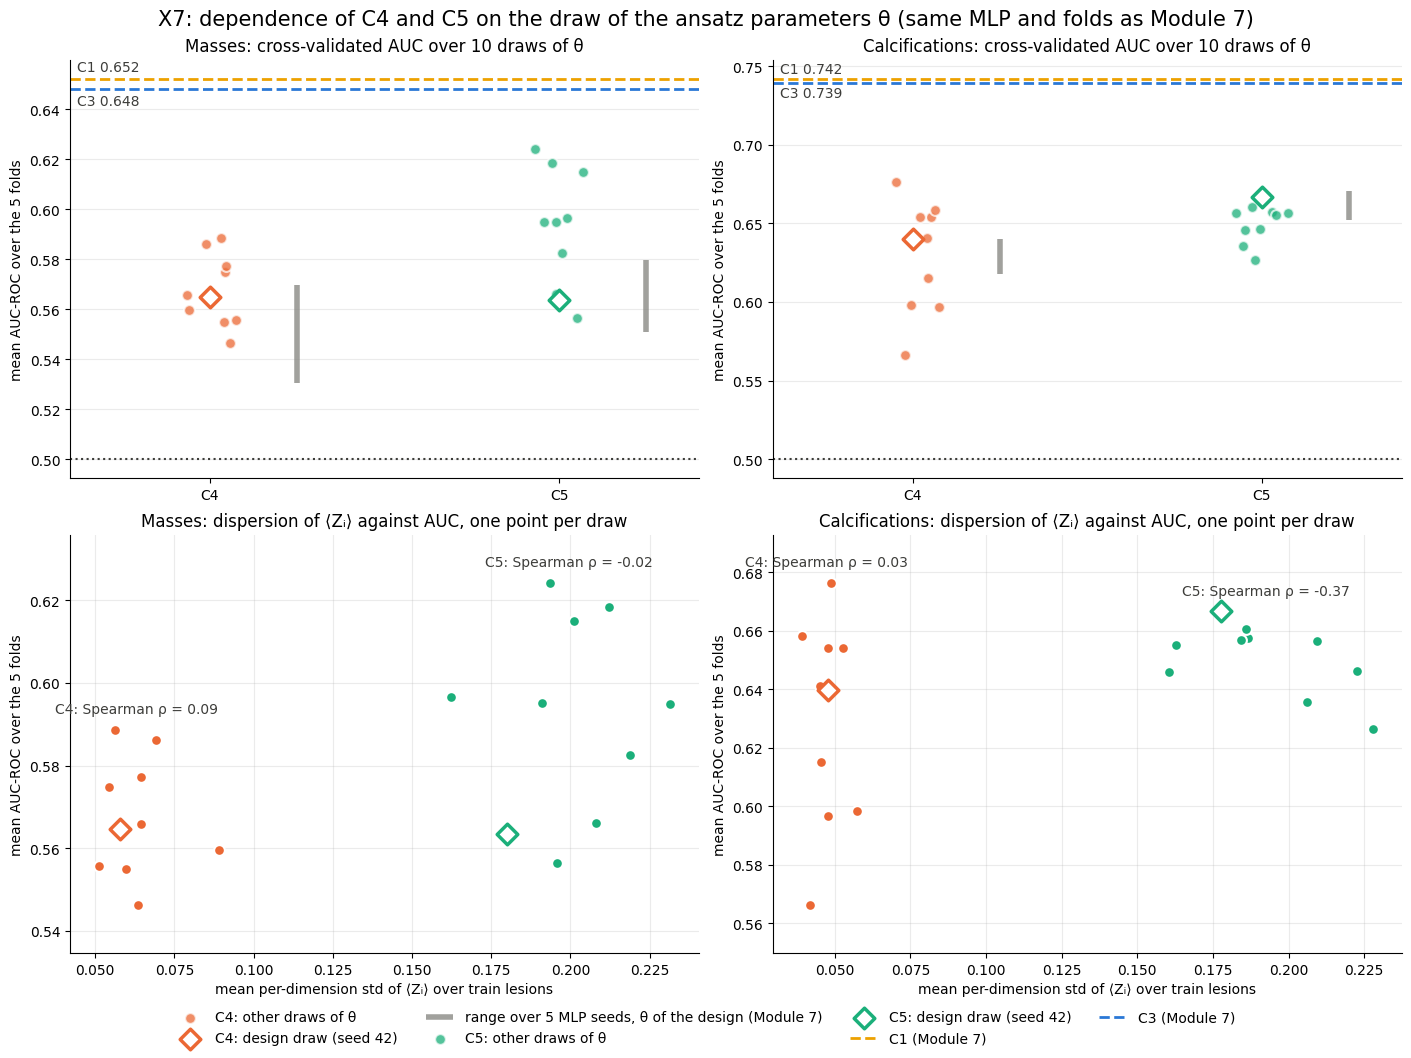

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), layout='constrained')
rng = np.random.default_rng(SEED)
for col, ft in enumerate(FINDINGS):
    ax = axes[0, col]
    for i, q in enumerate(QUANTUM):
        part = per_draw[(per_draw.finding_type == ft) & (per_draw.condition == q)]
        other = part[part.theta_seed != SEED]
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(other)), other.cv_auc_mean, s=60, color=COLORS[q], alpha=0.75, zorder=3,
                   edgecolor='white', linewidth=1.5, label=f'{q}: other draws of θ')
        d = part[part.theta_seed == SEED].cv_auc_mean.iloc[0]
        ax.scatter(i, d, marker='D', s=110, facecolor='white', edgecolor=COLORS[q], linewidth=2.5, zorder=4,
                   label=f'{q}: design draw (seed 42)')
        by_seed = mlp_seed_means.loc[(ft, q)]
        ax.vlines(i + 0.25, by_seed.min(), by_seed.max(), color=MUTED, lw=4, alpha=0.8, zorder=2,
                  label='range over 5 MLP seeds, θ of the design (Module 7)' if i == 0 else None)
    for ref, va, dy in [('C1', 'bottom', 0.002), ('C3', 'top', -0.002)]:
        ax.axhline(classical[(ft, ref)], color=COLORS[ref], ls='--', lw=2, zorder=1, label=f'{ref} (Module 7)')
        ax.text(-0.38, classical[(ft, ref)] + dy, f'{ref} {classical[(ft, ref)]:.3f}', color=INK, va=va, fontsize=10)
    ax.axhline(0.5, color=INK, ls=':', lw=1.5)
    ax.set_xticks([0, 1], QUANTUM)
    ax.set_xlim(-0.4, 1.4)
    ax.grid(axis='x', visible=False)
    ax.set(title=f'{TITLES[ft]}: cross-validated AUC over 10 draws of θ', ylabel='mean AUC-ROC over the 5 folds')
    ax = axes[1, col]
    for q in QUANTUM:
        part = per_draw[(per_draw.finding_type == ft) & (per_draw.condition == q)]
        ax.scatter(part.dispersion, part.cv_auc_mean, s=60, color=COLORS[q], edgecolor='white', linewidth=1.5, zorder=3)
        d = part[part.theta_seed == SEED]
        ax.scatter(d.dispersion, d.cv_auc_mean, marker='D', s=110, facecolor='white', edgecolor=COLORS[q], linewidth=2.5, zorder=4)
        rho = summary.set_index(['finding_type', 'condition']).loc[(ft, q), 'spearman_dispersion_auc']
        ax.annotate(f'{q}: Spearman ρ = {rho:.2f}', (part.dispersion.mean(), part.cv_auc_mean.max()), textcoords='offset points',
                    xytext=(0, 12), ha='center', color=INK, fontsize=10)
    ax.margins(y=0.15)
    ax.set(title=f'{TITLES[ft]}: dispersion of ⟨Zᵢ⟩ against AUC, one point per draw',
           xlabel='mean per-dimension std of ⟨Zᵢ⟩ over train lesions', ylabel='mean AUC-ROC over the 5 folds')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=10, frameon=False)
fig.suptitle('X7: dependence of C4 and C5 on the draw of the ansatz parameters θ (same MLP and folds as Module 7)', fontsize=15)
fig.savefig(FIG_DIR / 'X7_theta_draws.png', dpi=180, bbox_inches='tight')
plt.show()

#### **6° Verifications and files**

In [8]:
check('every fit stopped before the epoch limit', cv.epochs.max(), cv.epochs.max() < MAX_EPOCHS)
check('one cross-validation per subset, map and draw', cv.groupby(['finding_type', 'condition', 'theta_seed']).ngroups,
      cv.groupby(['finding_type', 'condition', 'theta_seed']).ngroups == 2 * 2 * len(THETA_SEEDS))
verifications = pd.DataFrame(checks)
cv.to_csv(RESULTS_DIR / 'X7_cv_por_fold.csv', index=False)
per_draw.to_csv(RESULTS_DIR / 'X7_sorteos.csv', index=False)
summary.to_csv(RESULTS_DIR / 'X7_resumen.csv', index=False)
verifications.to_csv(RESULTS_DIR / 'X7_verificaciones.csv', index=False)
display(verifications)
print(f'Checks passed: {int(verifications.passed.sum())}/{len(verifications)}')

,check,value,passed
0,theta seed 42 reproduces the theta of Module 5,0.0,True
1,mass: C4 with theta seed 42 equals the embeddi...,0.0,True
2,mass: C5 with theta seed 42 equals the embeddi...,0.0,True
3,calcification: C4 with theta seed 42 equals th...,0.0,True
4,calcification: C5 with theta seed 42 equals th...,0.0,True
5,mass: C4 with theta seed 42 reproduces the fol...,0.0,True
6,mass: C5 with theta seed 42 reproduces the fol...,0.0,True
7,calcification: C4 with theta seed 42 reproduce...,0.0,True
8,calcification: C5 with theta seed 42 reproduce...,0.0,True
9,every fit stopped before the epoch limit,105.0,True


Checks passed: 11/11


#### **7° Consequence**

**1. The draw of θ moves the AUC of C4 and C5, but none of the 40 draws reaches the classical conditions.**

| Mean CV AUC | Seed 42 (design) | Rank of seed 42 among 10 | Min – max over θ | Range over θ | Range over MLP seeds | C1 − best draw |
|---|---|---|---|---|---|---|
| Masses, C4 | 0.565 | 6 | 0.546 – 0.589 | 0.042 | 0.039 | 0.064 |
| Masses, C5 | 0.563 | 9 | 0.557 – 0.624 | 0.068 | 0.029 | 0.028 |
| Calcifications, C4 | 0.640 | 6 | 0.566 – 0.676 | 0.110 | 0.022 | 0.066 |
| Calcifications, C5 | 0.667 | 1 | 0.627 – 0.667 | 0.040 | 0.018 | 0.075 |

C1 scores 0.652 in masses and 0.742 in calcifications; C3, 0.648 and 0.739.

- **θ is a real source of variation.** Its spread is at least as large as that of the MLP seeds, and five times larger in calcifications with C4. A single draw cannot say how large the quantum deficit is.
- **Seed 42 is not a biased draw.** It is the 9th of 10 for C5 in masses, but the best for C5 in calcifications and in the middle for C4.
- **The best draw is an optimistic estimate,** because it is the maximum of ten noisy values selected on the same folds. Even so, it stays between 0.03 and 0.08 below C1.
- Across draws, the deficit against C1 ranges from 0.03 to 0.18.

**2. Dispersion does not predict AUC.** Over the ten draws, the Spearman correlation between the dispersion of ⟨Zᵢ⟩ and the AUC is 0.09 and −0.02 in masses and 0.03 and −0.37 in calcifications, with every p > 0.29. A more dispersed embedding is not a more informative one, which extends H-043 from the depth of the ansatz to its parameters.

**3. What θ does not touch.** The kernel metrics of Module 6, X2, the QSVM of X4 and X6 do not depend on θ, because the ansatz cancels in the fidelity. X4 already showed that the kernel of C4, read with an SVM, matches the classical SVM.

**For the thesis.**
- The conclusion of Module 7 (H-042) does not depend on the draw of θ; the size of the deficit does. Report the design value together with the range over draws.
- The test split was not used, so no draw was chosen on it.